# Parameter scans: what limits the replay?

One-at-a-time scans of the core parameters of the network (number of motifs, motif duration,
delay range, number of neurons, firing probability, firing threshold, bit-flip probability, and the
two initialisation flags), all the others being held at their `Params` defaults. Each value is run
`N_cv = 10` times: every run trains a new network on new motifs drawn from its own seed, a given seed
sharing its motifs across all the values of a parameter, and the replay from a seeded noisy trigger is
scored on the evoked window against the frozen motifs.

## Notebook summary

### Pipeline
1. Define the grids `scan_dicts` (13 values per parameter, 12 for `N_time`, 2 for each flag) and
   `N_cv = 10` runs per value, i.e. 940 runs in all.
2. For each parameter, take its `.lock`, read `<datetag>_scan_<key>.json` and, for each pair
   (value, `i_cv`) that is missing, reserve a placeholder row (`loss=null`, `time=0.0`), train a new
   network (`update_weight`, `learn_model`), replay it from a seeded noisy trigger and write the loss
   `1 - F1` in the reserved row.
3. Plot, for each parameter, the mean $F_1$ score (bars) with the 5%-95% quantiles of a beta fit
   (`get_beta_errorbar`) -> `scan_<key>.pdf`.

### Main outputs
- caches `../cached_data/<datetag>_scan_<key>.json` (columns `<key>`, `i_cv`, `loss`, `time`),
  one per parameter; complete since 2026-10-27 (940 runs, no placeholder row left);
- figures `scan_<key>.pdf`, one per parameter; `scan_num_delay`, `scan_N_neuron`, `scan_N_time` and
  `scan_N_pattern` form the scan figure of the paper, the scan of `p_A` is reported in its text only.

### Notes
- Reading of the complete scans: the replay fails for `num_delay` <= 15 and is reliable from 50; it
  fails for `N_neuron` <= 430 and is reliable from about 1500; both act through the mean number
  `p_A * N_neuron * num_delay` of spikes in a context window. The score decreases slowly with
  `N_time`, does not depend on `N_pattern` up to 26, and drops at `p_A` = 3e-2 (0.69, from 0.54 to
  0.78 across the runs). The cascade model (`get_f1_cascade`, `simulate_cascade`) predicts the
  thresholds of `num_delay` and `N_neuron` and a full recall from `p_A` = 3e-4; it is not yet drawn
  on the scan figures.
- A scan reserves a row before computing it: if the job dies, the row counts as computed forever.
  Remove it with `purge_unfinished_scans(datetag=f'{datetag}_scan')`, but only when no job is
  running (`squeue`), since the row of a live job looks the same and its result would be lost.
- The `.lock` is per parameter: a second job that finds it skips the parameter. The reserved rows,
  not the lock, keep several jobs from computing the same run, so that several jobs can share a
  parameter once its lock is removed by hand.
- The rows carry no date. Rows computed before the protocol change of 2026-10-26 (see `AGENTS.md`)
  were scored against an unseeded noisy realisation: the files of `N_time`, `lif_threshold`,
  `do_deconv` and `do_pinv` were last written before that date, the five others may mix both.

<!-- MNESIS-annotated -->

In [1]:
from mnesis_boilerplate import torch, np, pd, plt, data_cache, figpath, RECOMPUTE, DEBUG, datetag, loss_fn, Params
from mnesis_boilerplate import printfig, pprint, approx_equals, asdict, get_beta_errorbar
from mnesis_chains import StochasticSpikingPattern, HD_SNN
# RECOMPUTE = True


datetag = '2026-09-07'
Using device: mps


In [2]:
# from mnesis_boilerplate import purge_unfinished_scans
# purge_unfinished_scans(remove_locks=True, dry_run=False) # HACK

In [3]:
opt = Params()
opt

Params(datetag='2026-09-07', N_neuron=1024, num_delay=41, N_pattern=16, N_time=1000, N_pretime=50, p_A=0.00016, p_flip=0.01, seed=2026, lif_beta=0.7, lif_threshold=0.75, learn_beta=False, learn_threshold=False, do_pinv=True, do_deconv=True, num_epochs=256, num_warmup_epochs=16, base_lr=0.04, final_lr=0.0004, delta1=0.003, delta2=1e-05, dropout=0.6, alpha_surrogate=5.0, surrogate_name='FastSigmoid', loss_name='SpikeF1scoreLoss', reset_mechanism='zero', optimizer='adadelta', verbose=False, fig_width=15.92, phi=1.61803, fig_height=9.839125356142963, N_time_show=1000, N_neuron_show=1024, i_pattern=1, N_scan=14, N_cv=11)

In [4]:
N_cv = 10

In [5]:
print(f'Spikes in one target {opt.p_A * opt.N_neuron * opt.N_time:.1f},  in a SM window {opt.p_A * opt.N_neuron * opt.num_delay:.1f}')

Spikes in one target 163.8,  in a SM window 6.7


In [6]:
print(f'for a value {opt.lif_beta=:.1f}, the time constant is {- 1 / np.log(opt.lif_beta):.1f} steps')

for a value opt.lif_beta=0.7, the time constant is 2.8 steps


## scanning parameters

In [7]:
pprint('Scanning core network parameters to evaluate learning performance and robustness')

Scanning core network parameters to evaluate learning performance and robustness


In [8]:
import time
opt_scan = Params(datetag = datetag + '_scan')

N_scanning = 13 // DEBUG

scan_dicts= {'N_pattern' :  np.linspace(1, 26, N_scanning, dtype=int), # [3, 5, 7, 11,  13, 17], #  , 34, 55, 89, 144, 233, 377, 610, 987, 1364, 2351
             'N_time' : np.geomspace(100, 2000, N_scanning, dtype=int)[:-1], #[2**k for k in range(6, 12)],
             'num_delay' : np.linspace(1, 60, N_scanning, dtype=int), # [2, 3, 5, 8, 13, 21, 34, 55, 89],
             'N_neuron' : np.geomspace(50, 2000, N_scanning, dtype=int), # [55, 89, 144, 233, 377, 610, 987, 1364], #13, 21, 34, 
             'p_A': np.geomspace(0.0002, 0.05, N_scanning, dtype=float) , # [0.0002, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05], #0.00001, 0.00002, 0.00005, 0.0001, .. , 0.1, 0.5
             'lif_threshold': np.linspace(0.6, 1.05, N_scanning, dtype=float), 
             'do_deconv' : [True, False],
             'do_pinv' : [True, False],
             'p_flip': np.geomspace(1e-5, 1e-2, N_scanning, dtype=float), 
            }
label_dicts= {'N_pattern' : 'Number of motifs $M$',
             'N_time' : 'Motif duration $T$',
             'num_delay' : 'Delay range $D$',
             'N_neuron' : 'Number of neurons $N$',
             'p_A': 'Average firing',
             'lif_threshold': 'LIF threshold',
             'do_deconv' : 'Membrane deconvolution',
             'do_pinv' : 'Full pseudo-inverse computation',
              'p_flip': 'Bit flip probability',
            }


for key in scan_dicts:
    print(f"{50*'-'}\nscanning {key=}\n{50*'-'}", )
    filename = data_cache / f'{opt_scan.datetag}_{key}.json'
    lock_filename = filename.with_suffix('.lock')
    if RECOMPUTE : 
        filename.unlink(missing_ok=True) # FORCING RECOMPUTE
        lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE

    try:
        lock_filename.touch(exist_ok=False) # atomic (O_EXCL): fails if another process already holds this scan
    except FileExistsError:
        continue # running elsewhere, or a stale lock (see purge_unfinished_scans)
    try:
        # read the results only once the lock is held, so that they include the rows written by a previous holder
        if filename.exists():
            df_scan = pd.read_json(filename, orient='records')
        else:
            measure_columns = [key, 'i_cv', 'loss', 'time']
            df_scan = pd.DataFrame([], columns=measure_columns)
        # do print the progress if any item is not computed
        verb = any(df_scan[approx_equals(df_scan[key], value) & (df_scan["i_cv"] == i_cv)].empty
                   for value in scan_dicts[key] for i_cv in range(N_cv))
        for i_value, value in enumerate(np.random.permutation(scan_dicts[key])):
            # tolist() gives plain Python ints, so that the progress line reads i_cv=5 rather than i_cv=np.int64(5)
            for i_cv in np.random.permutation(N_cv).tolist():
                # Check if there's already a row with the same key value and i_cv
                mask = approx_equals(df_scan[key], value) & (df_scan["i_cv"] == i_cv)

                if df_scan[mask].empty :
                    if verb: print(f'|{i_cv=}| {i_value + 1}/{len(scan_dicts[key])}', end='\t')
                    # append a placeholder row with time zero to allow concurrent access to the file by other processes;
                    # read_json numbers the rows 0..n-1, so the label len(df_scan) is new and no computed row is overwritten
                    df_scan.loc[len(df_scan)] = {key:value, 'i_cv':i_cv, 'loss':float('inf'), 'time':0.0}
                    df_scan.to_json(filename, orient='records', indent=2)

                    # tic
                    since = time.time()
                    new_dict = asdict(opt_scan)
                    new_dict[key] = value
                    # the seed depends only on i_cv, not on the order of computation nor on the resumptions:
                    # each row is reproducible and a given i_cv shares the same motifs across the values of a key
                    new_dict['seed'] = opt_scan.seed + int(i_cv)
                    new_opt = Params(**new_dict)
                    new_hd = HD_SNN(new_opt, StochasticSpikingPattern())
         
                    new_hd.update_weight()
                    new_hd.learn_model(verbose=False)

                    try:
                        with torch.no_grad():
                            # seeded noisy cue, replay scored against the frozen motifs (as in notebooks 11-16);
                            # rows cached before 2026-10-26 were scored against an unseeded noisy realisation
                            target_ = new_hd.pattern_object(seed=new_opt.seed)
                            input_spikes = new_hd.get_input_spikes(target=target_, p_A=new_hd.opt.p_A, N_pretime=new_hd.opt.N_pretime, N_trigger_time=new_hd.opt.num_delay, N_time=new_hd.opt.N_time, seed=new_opt.seed)
                            _, _, spikes = new_hd.forward_pass(input_spikes)
                            spikes_ = spikes[:, :, (new_hd.opt.N_pretime+new_hd.opt.num_delay):(-new_hd.opt.N_pretime)]
                            loss_val = loss_fn(spikes_, new_hd.pattern_object.frozen_target[:, :, new_hd.opt.num_delay:]).item()
                    except Exception as e:
                        print(f"Error during evaluation: {e}")
                        loss_val = float('inf')  # Assign a large loss value to indicate failure
                        
                    # toc
                    elapsed_time = time.time() - since

                    df_scan = pd.read_json(filename, orient='records')
                    mask = approx_equals(df_scan[key], value) & (df_scan["i_cv"] == i_cv)
                    df_scan[['loss', 'time']] = df_scan[['loss', 'time']].astype(float)
                    df_scan.loc[mask, ['loss', 'time']] = [loss_val, elapsed_time]
                    df_scan.to_json(filename, orient='records', indent=2)
                    
                    if verb: 
                        # round before splitting, otherwise 119.97 s would read 1m 60.0s
                        minutes, seconds = divmod(round(elapsed_time, 1), 60)
                        print(f'|{key=}:{value=:.3e} \t| loss={loss_val:.3f}', end='\t')
                        print(f"| completed in {minutes:.0f}m {seconds:.1f}s |")
                else:
                    if verb: 
                        minutes, seconds = divmod(round(df_scan[mask]['time'].values[0], 1), 60)
                        print(f'|{key=}:{value=:.3e} \t | already computed for i_cv={i_cv}, skipping.', end='\t')
                        print(f"| completed in {minutes:.0f}m {seconds:.1f}s |")

    finally:
        # release the lock even after a crash or an interrupt; the placeholder row is then removed by purge_unfinished_scans
        lock_filename.unlink(missing_ok=True)

--------------------------------------------------
scanning key='N_pattern'
--------------------------------------------------
--------------------------------------------------
scanning key='N_time'
--------------------------------------------------
--------------------------------------------------
scanning key='num_delay'
--------------------------------------------------
--------------------------------------------------
scanning key='N_neuron'
--------------------------------------------------
--------------------------------------------------
scanning key='p_A'
--------------------------------------------------
--------------------------------------------------
scanning key='lif_threshold'
--------------------------------------------------


--------------------------------------------------
scanning key='do_deconv'
--------------------------------------------------
--------------------------------------------------
scanning key='do_pinv'
--------------------------------------------------


--------------------------------------------------
scanning key='p_flip'
--------------------------------------------------

--------------------------------------------------
scanning key='N_pattern'
--------------------------------------------------
Reading filename=PosixPath('../cached_data/2026-09-07_scan_N_pattern.json')...
     N_pattern  i_cv      loss         time  f1-score
0            7     5  0.205915  2396.009940  0.794085
1           26     6  0.172439  4251.827257  0.827561
2           26     5  0.157292  3930.556749  0.842708
3           26     2  0.140061  4684.240217  0.859939
4           26     8  0.173337  3368.868126  0.826663
..         ...   ...       ...          ...       ...
125          3     6  0.259023  1656.432011  0.740977
126         15     1  0.158246  3110.916741  0.841754
127         19     0  0.140870  4670.859410  0.859130
128          3     2  0.018028  1820.076785  0.981972
129         17     4  0.055675  2490.242644  0.944325

[130 rows x 5 columns]
Saving as ../figures/scan_N_pattern.pdf


Saving as ../figures/scan_N_pattern.png


Saving as ../figures/scan_N_pattern.svg


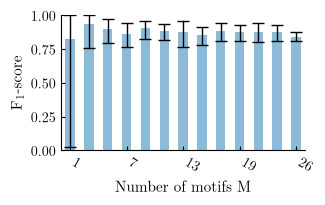

--------------------------------------------------
scanning key='N_time'
--------------------------------------------------
Reading filename=PosixPath('../cached_data/2026-09-07_scan_N_time.json')...
     N_time  i_cv      loss         time  f1-score
0       211     5  0.035409   514.435596  0.964591
1       211     9  0.047503   564.776256  0.952497
2       211     7  0.117371   474.756461  0.882629
3       945     1  0.129761  1934.598943  0.870239
4       211     6  0.044632   475.722298  0.955368
..      ...   ...       ...          ...       ...
115     128     3  0.008734   298.008322  0.991266
116     128     8  0.008969   339.567117  0.991031
117     128     5  0.017021   317.296767  0.982979
118     447     5  0.013274   882.249007  0.986726
119     100     7  0.057143   232.380915  0.942857

[120 rows x 5 columns]
Saving as ../figures/scan_N_time.pdf
Saving as ../figures/scan_N_time.png
Saving as ../figures/scan_N_time.svg


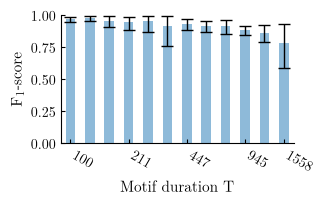

--------------------------------------------------
scanning key='num_delay'
--------------------------------------------------
Reading filename=PosixPath('../cached_data/2026-09-07_scan_num_delay.json')...
     num_delay  i_cv      loss         time  f1-score
0           15     5  0.999610  2179.675002  0.000390
1           15     9  0.999616  1744.300082  0.000384
2           15     7  0.999592  2200.188603  0.000408
3            1     3  1.000000  1484.662476  0.000000
4            1     7  1.000000  1935.022134  0.000000
..         ...   ...       ...          ...       ...
125          5     6  1.000000  1719.178746  0.000000
126         60     0  0.023085  2204.812919  0.976915
127         45     3  0.086983  2274.771672  0.913017
128         30     4  0.505103  1823.518524  0.494897
129          5     2  0.998479  1762.850845  0.001521

[130 rows x 5 columns]
Saving as ../figures/scan_num_delay.pdf
Saving as ../figures/scan_num_delay.png


Saving as ../figures/scan_num_delay.svg


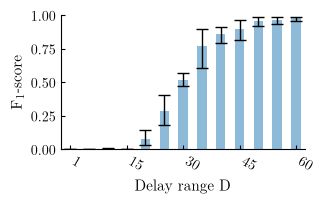

--------------------------------------------------
scanning key='N_neuron'
--------------------------------------------------
Reading filename=PosixPath('../cached_data/2026-09-07_scan_N_neuron.json')...
     N_neuron  i_cv      loss         time  f1-score
0        2000     3  0.022509  2946.214716  0.977491
1        2000     6  0.021229  2889.452100  0.978771
2        2000     5  0.020359  2871.585196  0.979641
3        2000     2  0.056098  2837.897155  0.943902
4        2000     8  0.019421  2860.581543  0.980579
..        ...   ...       ...          ...       ...
125       232     9  0.968000  1500.672887  0.032000
126       232     6  0.979557  1601.677062  0.020443
127       795     9  0.320561  1943.705035  0.679439
128       232     7  1.000000  1674.963653  0.000000
129       795     0  0.366637  2045.735683  0.633363

[130 rows x 5 columns]
Saving as ../figures/scan_N_neuron.pdf


Saving as ../figures/scan_N_neuron.png
Saving as ../figures/scan_N_neuron.svg


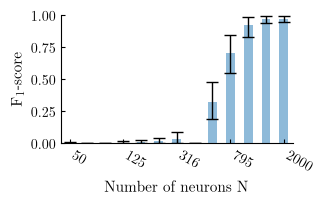

--------------------------------------------------
scanning key='p_A'
--------------------------------------------------
Reading filename=PosixPath('../cached_data/2026-09-07_scan_p_A.json')...
          p_A  i_cv      loss         time  f1-score
0    0.050000     3  0.108739  2107.370506  0.891261
1    0.003162     0  0.026120  2302.507790  0.973880
2    0.050000     5  0.108716  2141.158859  0.891284
3    0.050000     2  0.108157  2104.441058  0.891843
4    0.019921     1  0.061048  2808.030032  0.938952
..        ...   ...       ...          ...       ...
125  0.005010     6  0.009812  2577.936673  0.990188
126  0.007937     0  0.015275  2326.052908  0.984725
127  0.005010     1  0.009806  2156.750991  0.990194
128  0.005010     4  0.009742  2548.088666  0.990258
129  0.031560     1  0.258536  3338.705204  0.741464

[130 rows x 5 columns]
Saving as ../figures/scan_p_A.pdf


Saving as ../figures/scan_p_A.png
Saving as ../figures/scan_p_A.svg


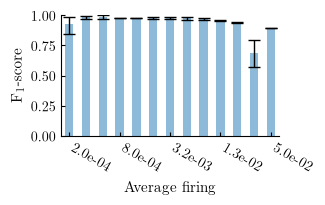

--------------------------------------------------
scanning key='lif_threshold'
--------------------------------------------------
Reading filename=PosixPath('../cached_data/2026-09-07_scan_lif_threshold.json')...
     lif_threshold  i_cv      loss         time  f1-score
0           0.7125     5  0.122021  2639.733740  0.877979
1           0.7125     9  0.118158  2614.613892  0.881842
2           0.7125     7  0.120017  2590.272344  0.879983
3           0.7125     8  0.059245  2714.336865  0.940755
4           0.7125     6  0.119234  3084.298638  0.880766
..             ...   ...       ...          ...       ...
125         0.8250     6  0.108769  2047.673324  0.891231
126         1.0125     1  1.000000  2182.498082  0.000000
127         1.0500     3  1.000000  2940.713028  0.000000
128         1.0125     3  1.000000  2178.038736  0.000000
129         0.8625     7  0.282818  2535.718406  0.717182

[130 rows x 5 columns]
Saving as ../figures/scan_lif_threshold.pdf


Saving as ../figures/scan_lif_threshold.png
Saving as ../figures/scan_lif_threshold.svg


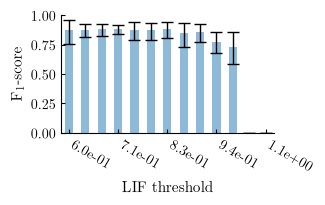

--------------------------------------------------
scanning key='do_deconv'
--------------------------------------------------
Reading filename=PosixPath('../cached_data/2026-09-07_scan_do_deconv.json')...
    do_deconv  i_cv      loss         time  f1-score
0        True     0  0.111824  3098.348683  0.888176
1        True     1  0.214923  2759.693664  0.785077
2        True     2  0.106265  2871.034452  0.893735
3        True     3  0.058313  2921.667443  0.941687
4        True     4  0.117301  2899.598389  0.882699
5        True     5  0.184100  2920.362912  0.815900
6        True     6  0.142002  2857.802707  0.857998
7        True     7  0.148784  2968.103649  0.851216
8        True     8  0.078633  2906.092801  0.921367
9        True     9  0.128732  2764.556605  0.871268
10      False     5  0.123859  3016.618532  0.876141
11      False     9  0.104434  2877.888148  0.895566
12      False     7  0.106655  2766.973186  0.893345
13      False     8  0.060663  2694.985537  0.939337

Saving as ../figures/scan_do_deconv.png
Saving as ../figures/scan_do_deconv.svg


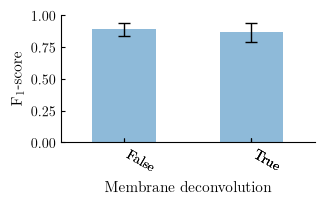

--------------------------------------------------
scanning key='do_pinv'
--------------------------------------------------
Reading filename=PosixPath('../cached_data/2026-09-07_scan_do_pinv.json')...
    do_pinv  i_cv      loss         time  f1-score
0      True     0  0.096774  2959.673100  0.903226
1      True     1  0.182021  3043.904157  0.817979
2      True     2  0.126010  2997.662065  0.873990
3      True     3  0.042647  2955.444406  0.957353
4      True     4  0.050122  2736.148267  0.949878
5      True     5  0.116070  2778.615113  0.883930
6      True     6  0.177019  2717.103452  0.822981
7      True     7  0.099277  2761.778470  0.900723
8      True     8  0.109963  2731.502217  0.890037
9      True     9  0.146677  2719.097740  0.853323
10    False     5  0.998708  1769.943036  0.001292
11    False     9  0.998742  1755.429639  0.001258
12    False     7  0.998642  1786.239497  0.001358
13    False     8  0.998573  1766.437789  0.001427
14    False     6  0.998682  1760

Saving as ../figures/scan_do_pinv.png
Saving as ../figures/scan_do_pinv.svg


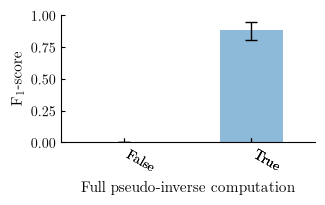

--------------------------------------------------
scanning key='p_flip'
--------------------------------------------------
Reading filename=PosixPath('../cached_data/2026-09-07_scan_p_flip.json')...
       p_flip  i_cv      loss         time  f1-score
0    0.010000     8  0.126222  2817.770676  0.873778
1    0.010000     1  0.135239  2754.651381  0.864761
2    0.010000     3  0.145893  2804.465313  0.854107
3    0.010000     9  0.058557  2646.026392  0.941443
4    0.010000     6  0.044983  2617.203593  0.955017
..        ...   ...       ...          ...       ...
125  0.000010     3  0.031377  2175.937872  0.968623
126  0.000010     2  0.101768  2182.942387  0.898232
127  0.000316     1  0.062069  2271.225978  0.937931
128  0.000100     2  0.118174  2049.484477  0.881826
129  0.000010     7  0.105673  2184.132065  0.894327

[130 rows x 5 columns]
Saving as ../figures/scan_p_flip.pdf


Saving as ../figures/scan_p_flip.png
Saving as ../figures/scan_p_flip.svg


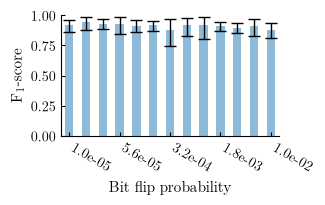

In [9]:
# from matplotlib import ticker

for key in scan_dicts:
    print(f"{50*'-'}\nscanning {key=}\n{50*'-'}", )
    filename = data_cache / f'{opt_scan.datetag}_{key}.json'
    lock_filename = filename.with_suffix('.lock')
    if not lock_filename.exists() and filename.exists():
        print(f'Reading {filename=}...')
        df_scan = pd.read_json(filename)
        # keep only the values of the current grid, as older grids may have left other values in the cache
        df_scan = df_scan[np.logical_or.reduce([approx_equals(df_scan[key], value) for value in scan_dicts[key]])]
        df_scan['f1-score'] = 1 - df_scan['loss']
        print(df_scan)
        # https://pandas.pydata.org/pandas-docs/stable/user_guide/visualization.html?highlight=errorbar#visualization-errorbars
        fig, ax = plt.subplots()
        gp_scan = df_scan.groupby(key)['f1-score']
        means = gp_scan.mean()
        # 5-95% quantiles of a beta fit, as in notebooks 14-16: with 10 runs the empirical
        # quantiles are close to the min-max range; one fit per value, since a resumed
        # scan may hold a different number of runs per value (unfinished rows are NaN)
        err = np.hstack([get_beta_errorbar(scores.dropna().to_numpy()[None, :])[1] for _, scores in gp_scan])

        means.plot.bar(yerr=err, ax=ax, capsize=4, rot=-75,
                       legend=False, alpha=.5)

        ax.set_ylabel(r"$F_1$-score")
        ax.set_xlabel(label_dicts[key])

        # Show only min, median, max ticks with compact labels
        n = len(means)
        # tick_indices = [0, n // 2, n - 1]
        tick_indices = [0, n // 4, n // 2, (3*n) // 4, n - 1]
        all_xticks = ax.get_xticks()
        selected_ticks = all_xticks[:n][tick_indices]
        tick_values = means.index[tick_indices].tolist()
        tick_labels = [str(v) if isinstance(v, bool) else f'{v:.1e}' if isinstance(v, float) else str(int(v)) if isinstance(v, int) else str(v) for v in tick_values]
        ax.set_xticks(selected_ticks)
        ax.set_xticklabels(tick_labels, rotation=-30, ha='left')

        ax.set_ylim(0, 1)
        # 2 x 2 panels in fig:scan, each printed at half the text width (scale 1, golden ratio)
        printfig(fig, 'scan_' + key, fig_width=opt_scan.fig_width/2, fig_height=opt_scan.fig_height/2, figpath=figpath)
        plt.show()